# Shared conventions for students

Make sure that independent simulation runs use fresh random draws. Include the actual numerical parameters, algorithm, and step size in the report. Where two models are compared, use matched initial configurations adapted to their respective state spaces.

For a graph with adjacency matrix $A_{ij}$ the degree of vertex $i$ is $d_i = \sum_j A_{ij}$. The *empirical mean* is the average over agents

$$
m(t) = \frac{1}{N}\sum_{i=1}^N X_i(t),
$$

and a common disagreement measure is

$$
V(t) = \frac{1}{N}\sum_{i=1}^N |X_i(t) - m(t)|^2,
$$

where $|\cdot|$ denotes absolute value for scalar states and Euclidean norm for vectors.

# Project 2: Small-World Shortcuts and Epidemic Spreading

## Central question

Does adding long-range contacts to a local contact network change how often a finite epidemic develops into a large outbreak?

## Models

Consider a continuous-time *SIS Markov jump process* on an undirected contact network $A$. An infected vertex $I = 1$ recovers at rate $\gamma$; a susceptible vertex $I = 0$ is infected at rate $\beta$ times the number of infected neighbours:

$$
I_i : 0 \to 1 \text{ at rate } \beta \sum_j A_{ij} I_j, \qquad I_i : 1 \to 0 \text{ at rate } \gamma.
$$

The state is $I \in \{0,1\}^N$; the all-susceptible state is absorbing.

## Project requirements

1. **Networks.** Let $N = 40$. Construct (A) the degree-4 ring lattice and (B) a Watts–Strogatz graph obtained by rewiring ring edges with probability $p = 0.20$, e.g. `watts_strogatz_graph(40,4,0.2,seed=7)`; regenerate if disconnected. Keep the edge count unchanged. Report mean degree, clustering coefficient, and a graph drawing.
2. **Rates and generator.** Derive infection and recovery rates. For the total number of infected $F(I) = \sum_i I_i$, show that $(\mathcal{L}F)(I)$ is the sum of infection rates minus the sum of recovery rates. Explain why configurations with the same infected count can have different expected instantaneous changes.
3. **Initial state and parameters.** Start with only vertices 0 and 1 infected on each graph. Set $\gamma = 1$ and compare $\beta = 0.25$ and $0.50$. Run until $T = 20$ or until infection extinction.
4. **Gillespie experiment.** For each of the four graph/$\beta$ conditions, simulate 40 independent trajectories. Record the infected count $F(I(t))$, peak infected fraction $\max_{t \le T} F(I(t))/N$, and whether the count reaches 10 by $T$. Record extinction times where observed; do not call $T$ an extinction time for surviving trajectories.
5. **Comparison and robustness.** Estimate the fraction of runs reaching 10 infections and compare peak-infection distributions. Generate one additional small-world graph using another seed, with epidemic parameters unchanged, to assess graph-to-graph variability.

## Final discussion

Explain what the numerical results show about shortcuts. Distinguish trends from assertions about all small-world networks.

# Implementation

#### Imports

In [657]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd


### Setup

#### 1. Networks

In [658]:
# Fixed project parameters (Project 2 brief)
N = 40          # number of agents / vertices
K = 4           # ring lattice degree (2 neighbours on each side)
P_REWIRE: float = 0.20 # Watts–Strogatz rewiring probability
SEED_WS = 13    # graph seed for the Watts–Strogatz realization

G_ring : nx.Graph = nx.circulant_graph(N, [1, 2])
G_watts_strogatz : nx.Graph = nx.watts_strogatz_graph(N, K, P_REWIRE, seed=SEED_WS)
assert nx.is_connected(G_watts_strogatz), "regenerate with another seed"

print("G_ring properties:")
print(f" - Connected: {'✔' if nx.is_connected(G_ring) else '✘'}")
print(f" - Mean degree: {2*G_ring.number_of_edges() / G_ring.number_of_nodes()}")
print(f" - Clustering coefficient: {nx.average_clustering(G_ring):0.2}")
print("G_watts_strogatz properties:")
print(f" - Connected: {'✔' if nx.is_connected(G_watts_strogatz) else '✘'}")
print(f" - Mean degree: {2*G_watts_strogatz.number_of_edges() / G_watts_strogatz.number_of_nodes()}")
print(f" - Clustering coefficient: {nx.average_clustering(G_watts_strogatz):0.2}")


G_ring properties:
 - Connected: ✔
 - Mean degree: 4.0
 - Clustering coefficient: 0.5
G_watts_strogatz properties:
 - Connected: ✔
 - Mean degree: 4.0
 - Clustering coefficient: 0.4


Drawing the graphs

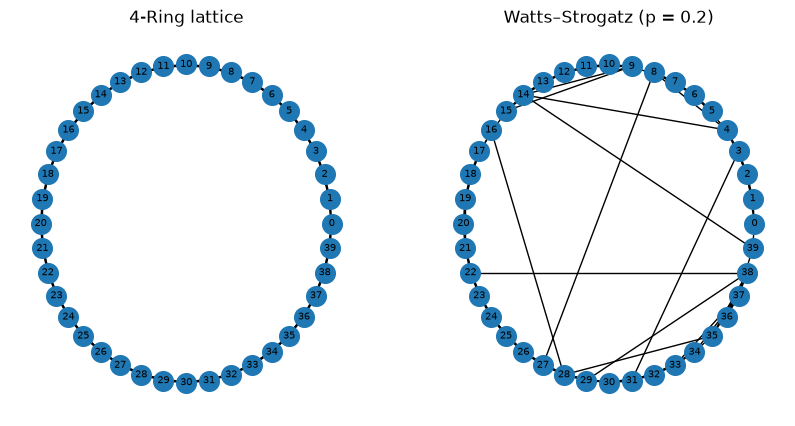

In [659]:
fig, axes = plt.subplots(1,2,figsize=(10,5))

for ax, G, title in zip(axes, [G_ring, G_watts_strogatz], ["4-Ring lattice", f"Watts–Strogatz (p = {P_REWIRE:.2})"]):
    nx.draw(G, pos=nx.circular_layout(G), ax=ax, with_labels=True,
            node_size=200, font_size=7)
    ax.set_title(title)

plt.show()

#### 2. Rates and generator

Derive infection and recovery rates. For the total number of infected $F(I) = \sum_i I_i$, show that $(\mathcal{L}F)(I)$ is the sum of infection rates minus the sum of recovery rates. Explain why configurations with the same infected count can have different expected instantaneous changes.

$$
\begin{aligned}
(\mathcal{L}F)(I)&=\sum_{\text{jumps r}}\lambda_r (I) [F(I + v_r )- F(I)] \\
(\mathcal{L}F)(I)&=\sum_{i}\lambda_i^{inf} (I) (+1) + \sum_i \lambda_i^{rec} (I) (-1) \\
(\mathcal{L}F)(I)&=\sum_{i}\lambda_i^{inf} (I) - \sum_i \lambda_i^{rec} (I) \\
(\mathcal{L}F)(I)&=\sum_{i}\beta(1-I_i)\sum_j A_{ij}I_j - \sum_i \gamma I_i\\
(\mathcal{L}F)(I)&=\beta\sum_{i}(1-I_i)\sum_j A_{ij}I_j - \gamma F(I)\\
\end{aligned}
$$


The right side, $\gamma F(I)$ only depends on how many vertices are infected.

The left side adds up over susceptible vertices, the number of infected neighbours each has. That equals $\beta$ times the number of S-I edges, which depends on where the infected vertices are.

In [660]:
def generator_F(graph, I, beta, gamma):
    """(LF)(I) = beta * #S-I edges - gamma * F(I), the expected instantaneous change of F."""
    A = nx.to_numpy_array(graph, nodelist=range(graph.number_of_nodes()))
    I = np.asarray(I)
    si_edges = ((1 - I) * (A @ I)).sum()  # sum over susceptible i of infected neighbours
    F = I.sum()
    return {"S-I edges": int(si_edges), "F": int(F),
            "infection rate": beta * si_edges, "recovery rate": gamma * F,
            "LF": beta * si_edges - gamma * F}


def config(n, infected):
    """Configuration vector with the given vertices infected."""
    I = np.zeros(n, dtype=int)
    I[list(infected)] = 1
    return I


# L F at the initial state (vertices 0 and 1 infected) for the four graph/beta conditions
rows = []
for graph_name, G in [("Ring lattice", G_ring), ("Watts–Strogatz", G_watts_strogatz)]:
    for beta in [0.25, 0.5]:
        rows.append({"graph": graph_name, "beta": beta,
                     "deg(0), deg(1)": (G.degree(0), G.degree(1)),
                     **generator_F(G, config(N, [0, 1]), beta, gamma=1.0)})
pd.DataFrame(rows)

,graph,beta,"deg(0), deg(1)",S-I edges,F,infection rate,recovery rate,LF
0,Ring lattice,0.25,"(4, 4)",6,2,1.5,2.0,-0.5
1,Ring lattice,0.50,"(4, 4)",6,2,3.0,2.0,1.0
2,Watts–Strogatz,0.25,"(3, 3)",4,2,1.0,2.0,-1.0
3,Watts–Strogatz,0.50,"(3, 3)",4,2,2.0,2.0,0.0


#### 3. Initial state and parameters

Start with only vertices 0 and 1 infected on each graph. Set $\gamma = 1$ and compare $\beta = 0.25$ and $0.50$. Run until $T = 20$ or until infection extinction.

###### Simulation setup

Gillespie algorithm. At the current state $I$ and time $t$:

1. Compute all flip rates $q_i(I) = \beta(1-I_i)\sum_j A_{ij}I_j + \gamma I_i$ and the total rate $\Lambda(I) = \sum_i q_i(I)$.
2. If $\Lambda(I) = 0$, stop (absorbing all-susceptible state).
3. Draw a waiting time $\tau \sim \mathrm{Exp}(\Lambda(I))$. If $t + \tau > T$, stop.
4. Choose vertex $i$ with probability $q_i(I)/\Lambda(I)$.
5. Update $t \leftarrow t + \tau$, $I_i \leftarrow 1 - I_i$; repeat.

There is no fixed time step: every sampled event changes the state.


In [662]:
def gillespie_sis(graph : nx.Graph, inf_rate, rec_rate, initial_infected, max_time, seed):
    n = graph.number_of_nodes()
    A = nx.to_numpy_array(graph, nodelist=range(n)) #adjacency matrix
    rng = np.random.default_rng(seed)
    
    I = np.zeros(n,dtype=int)
    I[initial_infected] = 1
    

    t = 0.0
    times = [0.0]
    states = [I.copy()]

    # F(I(t))
    counts = [I.sum()]
    while True:
        rates = inf_rate*(1-I)*(A@I) + rec_rate*I
        total = rates.sum()

        # 2. absorbing state
        if total == 0:
            break

        # 3. waiting time until the next jump
        tau = rng.exponential(1/total)
        if t + tau > max_time:
            break

        # 4. pick which vertex flips, with probability rate/total
        i = rng.choice(n, p = rates/total)

        # 5. update time and state
        t += tau
        I[i] = 1 - I[i]
        times.append(t)
        counts.append(I.sum())
        states.append(I.copy())

    return np.array(times), np.array(counts), states


In [663]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def animate_run(graph, times, states, max_time, dt=0.1, speed=1.0):
    end = times[-1] if states[-1].sum() == 0 else max_time
    frame_times = np.arange(0, end + dt, dt)
    pos = nx.circular_layout(graph)
    fig, ax = plt.subplots(figsize=(6, 6))

    # draw once
    nx.draw_networkx_edges(graph, pos, ax=ax, alpha=0.4)
    nx.draw_networkx_labels(graph, pos, ax=ax, font_size=7)
    nodes = nx.draw_networkx_nodes(graph, pos, ax=ax, node_size=200,
                                   node_color=["lightblue"] * len(states[0]))
    ax.axis("off")

    def update(t):
        k = np.searchsorted(times, t, side="right") - 1
        I = states[k]
        nodes.set_facecolor(["red" if s == 1 else "lightblue" for s in I])
        ax.set_title(f"t = {t:.1f},  F = {I.sum()}")

    anim = FuncAnimation(fig, update, frames=frame_times, interval=1000 * dt / speed)
    plt.close(fig)
    css = "<style>.animation { display: inline-flex; flex-direction: column-reverse; }</style>"
    return HTML(anim.to_jshtml(default_mode="once") + css)


Example: a single trajectory (ring lattice, $\beta = 0.5$, $\gamma = 1$, vertices 0 and 1 initially infected, $T = 20$). Uncomment the last line to animate it.


In [ ]:
times, counts, states = gillespie_sis(G_ring, inf_rate=0.5, rec_rate=1.0,
                                     initial_infected=[0, 1], max_time=20.0, seed=3745)
print(f"{len(times) - 1} events, peak F = {counts.max()}, final F = {counts[-1]} at t = {times[-1]:.2f}")
# animate_run(G_ring, times, states, max_time=20.0, speed=2)


#### 4. Gillespie Experiment

In [668]:
def run_experiment(graph, beta, gamma, initial_infected, t_max, n_runs, seed, outbreak_threshold=10):
    """Run n_runs independent Gillespie SIS trajectories and collect the tracked data.

    Returns
    -------
    trajectories : list of (times, counts) per run, i.e. F(I(t)) as a step function.
        The last entry is the last event, not t_max (surviving runs are not padded).
    summary : DataFrame, one row per run, with
        peak_fraction    max_{t <= T} F(I(t)) / N
        outbreak         True if F reached outbreak_threshold by T
        extinct          True if the infection died out before T
        extinction_time  time of extinction, NaN for surviving runs
    si_paths : list of arrays per run, number of S-I edges in each visited state
        (aligned with times/counts). beta * S-I edges is the total infection rate.
    """
    n = graph.number_of_nodes()
    A = nx.to_numpy_array(graph, nodelist=range(n))
    seeds = np.random.SeedSequence(seed).spawn(n_runs)

    trajectories = []
    si_paths = []
    rows = []
    for run, run_seed in enumerate(seeds):
        times, counts, states = gillespie_sis(graph, beta, gamma, initial_infected, t_max, run_seed)
        trajectories.append((times, counts))

        # S-I edges per state: sum over susceptible i of infected neighbours (as in L F).
        # Computed here and the states discarded, to keep memory small for many runs.
        S = np.array(states)
        si_paths.append(((1 - S) * (S @ A)).sum(axis=1).astype(int))

        extinct = counts[-1] == 0
        rows.append({
            "run": run,
            "peak_fraction": counts.max() / n,
            "outbreak": counts.max() >= outbreak_threshold,
            "extinct": extinct,
            "extinction_time": times[-1] if extinct else np.nan,
        })

    summary = pd.DataFrame(rows).set_index("run")
    return trajectories, summary, si_paths

In [669]:
# Plotting helpers. Each panel function draws one case (a summary returned by run_case)
# onto a given matplotlib axis, so the same panel can be used in the per-case figure
# and in the side-by-side comparison figures.
#
# Axis limits are cut to the data to avoid empty space. Pass the same `lim` (from
# tight_limits(all compared cases)) to every panel that should be comparable.

def tight_limits(summaries):
    """Shared axis maxima (xmax, ymax) per panel type, over all given cases."""
    def pad(v, margin=0.08):
        return v * (1 + margin)

    t_max = max(s.attrs["t_max"] for s in summaries)
    n = max(s.attrs["n"] for s in summaries)
    threshold = max(s.attrs["outbreak_threshold"] for s in summaries)

    # Trajectories: x up to the last time anything happens (t_max if any run survives),
    # y up to the highest count, but always showing the outbreak threshold line.
    t_end = max((times[-1] if counts[-1] == 0 else t_max)
                for s in summaries for times, counts in s.attrs["trajectories"])
    f_max = max(counts.max() for s in summaries for _, counts in s.attrs["trajectories"])

    # Peak fraction: x up to the largest peak (and the threshold line), y up to the
    # most runs sharing one peak value.
    peak_max = max(s["peak_fraction"].max() for s in summaries)
    freq_max = max(np.unique(np.round(s["peak_fraction"] * n), return_counts=True)[1].max()
                   for s in summaries)

    # Extinction: x up to the latest extinction, y up to the largest extinct fraction.
    ext_times = [s["extinction_time"].max() for s in summaries if s["extinct"].any()]
    ext_frac = max(s["extinct"].mean() for s in summaries)

    return {
        "traj": (min(t_end * 1.02, t_max), pad(max(f_max, threshold))),
        "peak": (min(max(peak_max, threshold / n) + 2 / n, 1 + 1 / n), pad(freq_max)),
        "ext":  (min(pad(max(ext_times), 0.04), t_max) if ext_times else t_max,
                 min(ext_frac + 0.05, 1.02) if ext_times else 1.02),
    }


def plot_trajectories(ax, summary, title="Infected count per run", lim=None):
    """F(I(t)) for every run + mean over runs."""
    a = summary.attrs
    t_max, threshold = a["t_max"], a["outbreak_threshold"]
    lim = lim or tight_limits([summary])["traj"]

    grid = np.linspace(0, t_max, 1001)
    on_grid = np.empty((len(a["trajectories"]), len(grid)))
    for k, (times, counts) in enumerate(a["trajectories"]):
        # Surviving runs: hold the last count until t_max (no event after the last jump).
        # Extinct runs stop at their extinction time.
        if counts[-1] > 0:
            times = np.append(times, t_max)
            counts = np.append(counts, counts[-1])
        ax.step(times, counts, where="post", alpha=0.3, linewidth=1)
        # Step function evaluated on the grid; extinct runs stay at 0 after extinction.
        on_grid[k] = counts[np.searchsorted(times, grid, side="right") - 1]
    ax.plot(grid, on_grid.mean(axis=0), color="black", linewidth=2.5, label="mean over runs")
    ax.axhline(threshold, color="red", linestyle="--", linewidth=1,
               label=f"outbreak threshold ({threshold})")
    ax.set_xlim(0, lim[0])
    ax.set_ylim(0, lim[1])
    ax.set_xlabel("t")
    ax.set_ylabel("F(I(t))  (number infected)")
    ax.set_title(title)
    ax.legend(loc="best")


def plot_peak(ax, summary, title=None, lim=None):
    """Peak infected fraction is discrete (multiples of 1/N): one point per value that
    occurred, height = number of runs with that peak. Red = outbreak (peak >= threshold)."""
    a = summary.attrs
    n, threshold, n_runs = a["n"], a["outbreak_threshold"], len(summary)
    lim = lim or tight_limits([summary])["peak"]

    peak = summary["peak_fraction"]
    values, freq = np.unique(np.round(peak * n).astype(int), return_counts=True)
    is_outbreak = values >= threshold
    if (~is_outbreak).any():
        ax.stem(values[~is_outbreak] / n, freq[~is_outbreak], basefmt=" ",
                linefmt="C0-", markerfmt="C0o", label="no outbreak")
    if is_outbreak.any():
        ax.stem(values[is_outbreak] / n, freq[is_outbreak], basefmt=" ",
                linefmt="red", markerfmt="ro", label="outbreak")
    ax.axvline(threshold / n, color="red", linestyle="--", linewidth=1)
    ax.set_xlim(0, lim[0])
    ax.set_ylim(0, lim[1])
    ax.set_xlabel("peak infected fraction  max F / N")
    ax.set_ylabel("runs")
    stats = f"mean {peak.mean():.3f}, outbreaks {summary['outbreak'].sum()}/{n_runs}"
    ax.set_title(f"{title}\n{stats}" if title else f"Peak fraction ({stats})")
    ax.legend(loc="upper right")


def plot_extinction(ax, summary, color=None, label=None, title=None, lim=None):
    """Extinction times as an empirical CDF: one point per extinct run, height =
    fraction of ALL runs extinct by that time. The curve levels off at the extinct
    fraction; the gap to 1 is the runs still alive at T. Can be called several times
    on the same axis to overlay cases."""
    n_runs = len(summary)
    lim = lim or tight_limits([summary])["ext"]

    ext = np.sort(summary["extinction_time"].dropna().to_numpy())
    frac = np.arange(1, len(ext) + 1) / n_runs
    count = f"{len(ext)}/{n_runs} runs extinct"
    line, = ax.step(ext, frac, where="post", alpha=0.4, color=color)
    # Points carry the legend entry; still drawn (empty) when no run went extinct.
    ax.plot(ext, frac, "o", markersize=4, color=line.get_color(),
            label=f"{label} ({count})" if label else count)
    ax.set_xlim(0, lim[0])
    ax.set_ylim(0, lim[1])
    ax.set_xlabel("extinction time t")
    ax.set_ylabel("fraction of runs extinct by t")
    ax.set_title(title or "Extinction time")
    ax.legend(loc="lower right")


def plot_experiment(summary):
    """Three panels for one case: trajectories, peak fraction, extinction time."""
    fig, (ax_traj, ax_peak, ax_ext) = plt.subplots(1, 3, figsize=(17, 4.5))
    fig.suptitle(summary.attrs["title"])
    plot_trajectories(ax_traj, summary)
    plot_peak(ax_peak, summary)
    plot_extinction(ax_ext, summary)
    fig.tight_layout()
    plt.show()


def run_case(graph, beta, seed, graph_name="", gamma=1.0, initial_infected=[0, 1],
             t_max=20.0, n_runs=40, outbreak_threshold=10):
    """Run one graph/beta condition, plot it, and return the per-run summary table.

    The trajectories and case settings are kept in `summary.attrs`, so the case
    can be re-plotted later with the panel functions above.
    """
    trajectories, summary, si_paths = run_experiment(graph, beta, gamma, initial_infected, t_max,
                                           n_runs, seed, outbreak_threshold)
    summary.attrs = dict(
        trajectories=trajectories, si_edges=si_paths, n=graph.number_of_nodes(), t_max=t_max,
        outbreak_threshold=outbreak_threshold, graph_name=graph_name, beta=beta, gamma=gamma,
        title=f"{graph_name}  β = {beta}, γ = {gamma}, {n_runs} runs, T = {t_max}",
    )
    plot_experiment(summary)
    return summary

Case 1: 
- Graph: 4-Ring Lattice
- Infected vertices: 0 and 1
- $\gamma = 1$, $\beta = 0.25$
- Max time: 20

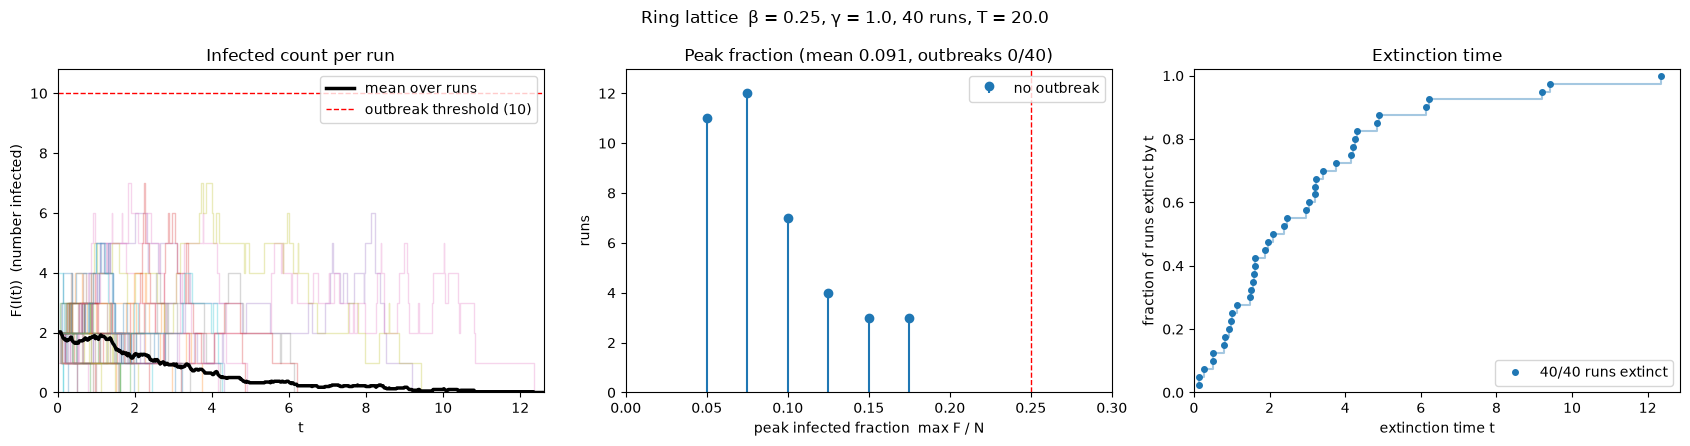

In [670]:
summary_ring_025 = run_case(G_ring, 0.25, seed=1100, graph_name="Ring lattice")

Case 2: 
- Graph: 4-Ring Lattice
- Infected vertices: 0 and 1
- $\gamma = 1$, $\beta = 0.5$
- Max time: 20

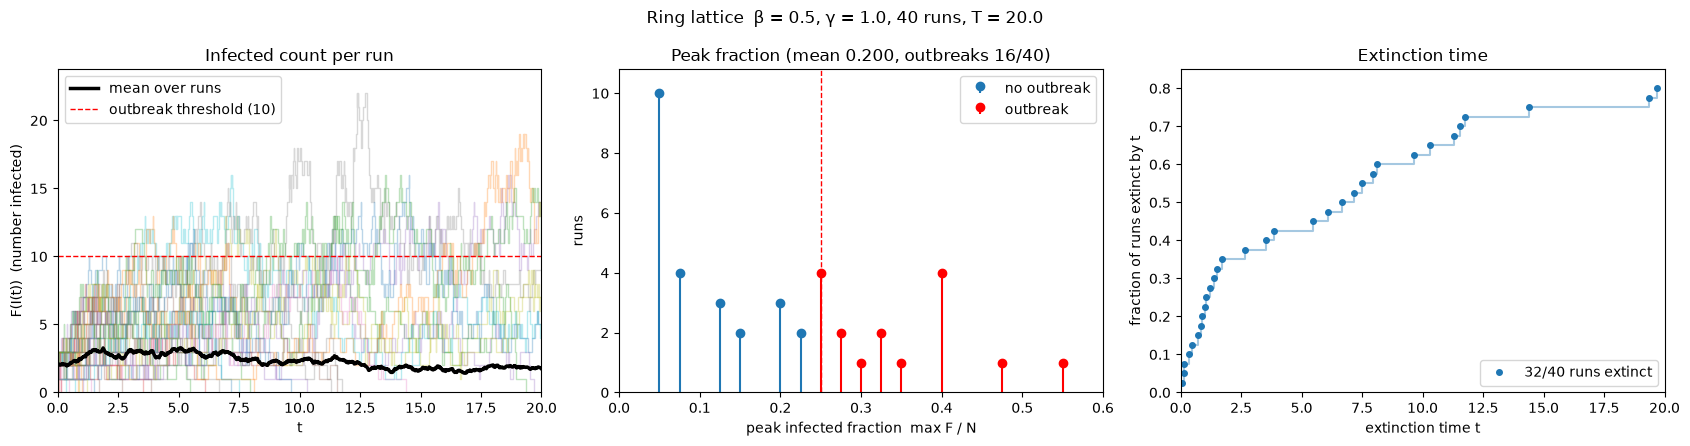

In [671]:
summary_ring_05 = run_case(G_ring, 0.5, seed=2200, graph_name="Ring lattice")

Case 3:
- Graph: Watts–Strogatz ($p = 0.2$)
- Infected vertices: 0 and 1
- $\gamma = 1$, $\beta = 0.25$
- Max time: 20

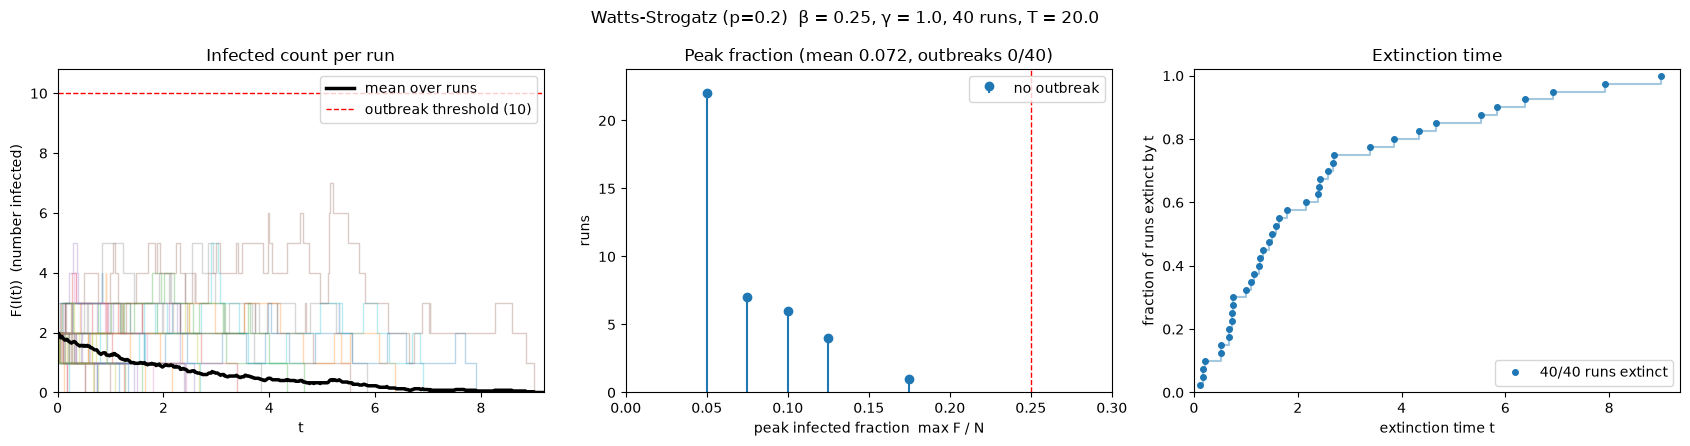

In [672]:
summary_watts_strogatz_025 = run_case(G_watts_strogatz, 0.25, seed=3300, graph_name="Watts-Strogatz (p=0.2)")

Case 4:
- Graph: Watts–Strogatz ($p = 0.2$)
- Infected vertices: 0 and 1
- $\gamma = 1$, $\beta = 0.5$
- Max time: 20

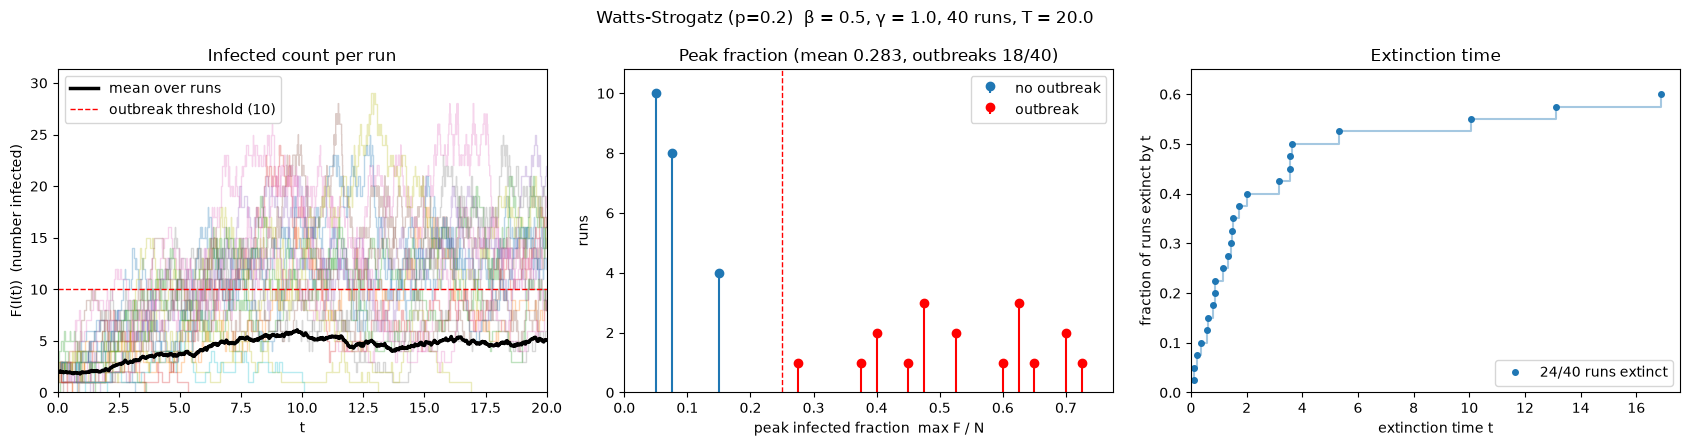

In [673]:
summary_watts_strogatz_05 = run_case(G_watts_strogatz, 0.5, seed=4400, graph_name="Watts-Strogatz (p=0.2)")

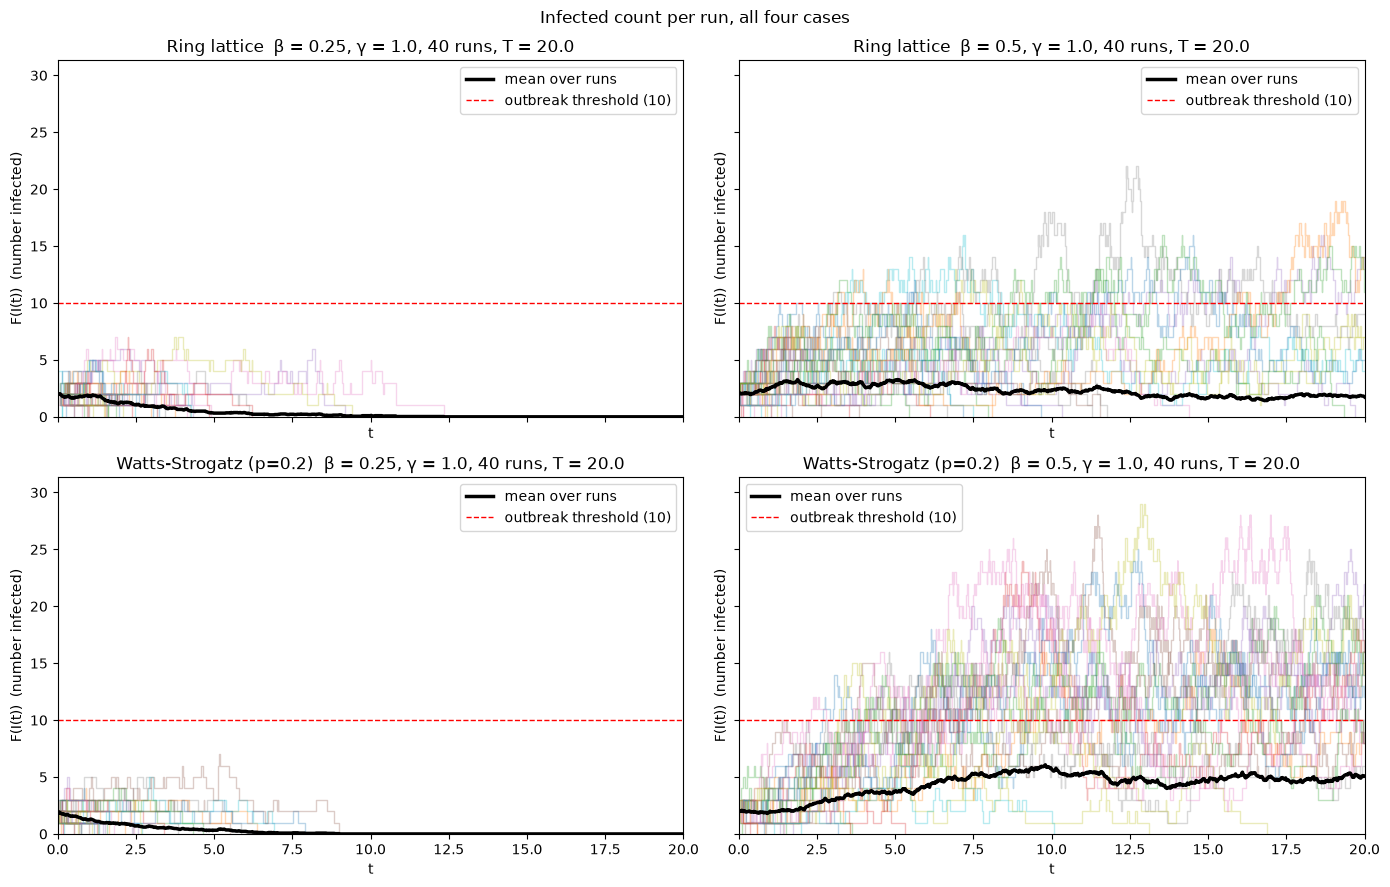

In [674]:
cases = [summary_ring_025, summary_ring_05,
         summary_watts_strogatz_025, summary_watts_strogatz_05]
lim = tight_limits(cases)  # shared by all comparison figures below

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, summary in zip(axes.flat, cases):
    plot_trajectories(ax, summary, title=summary.attrs["title"], lim=lim["traj"])
fig.suptitle("Infected count per run, all four cases")
fig.tight_layout()
plt.show()

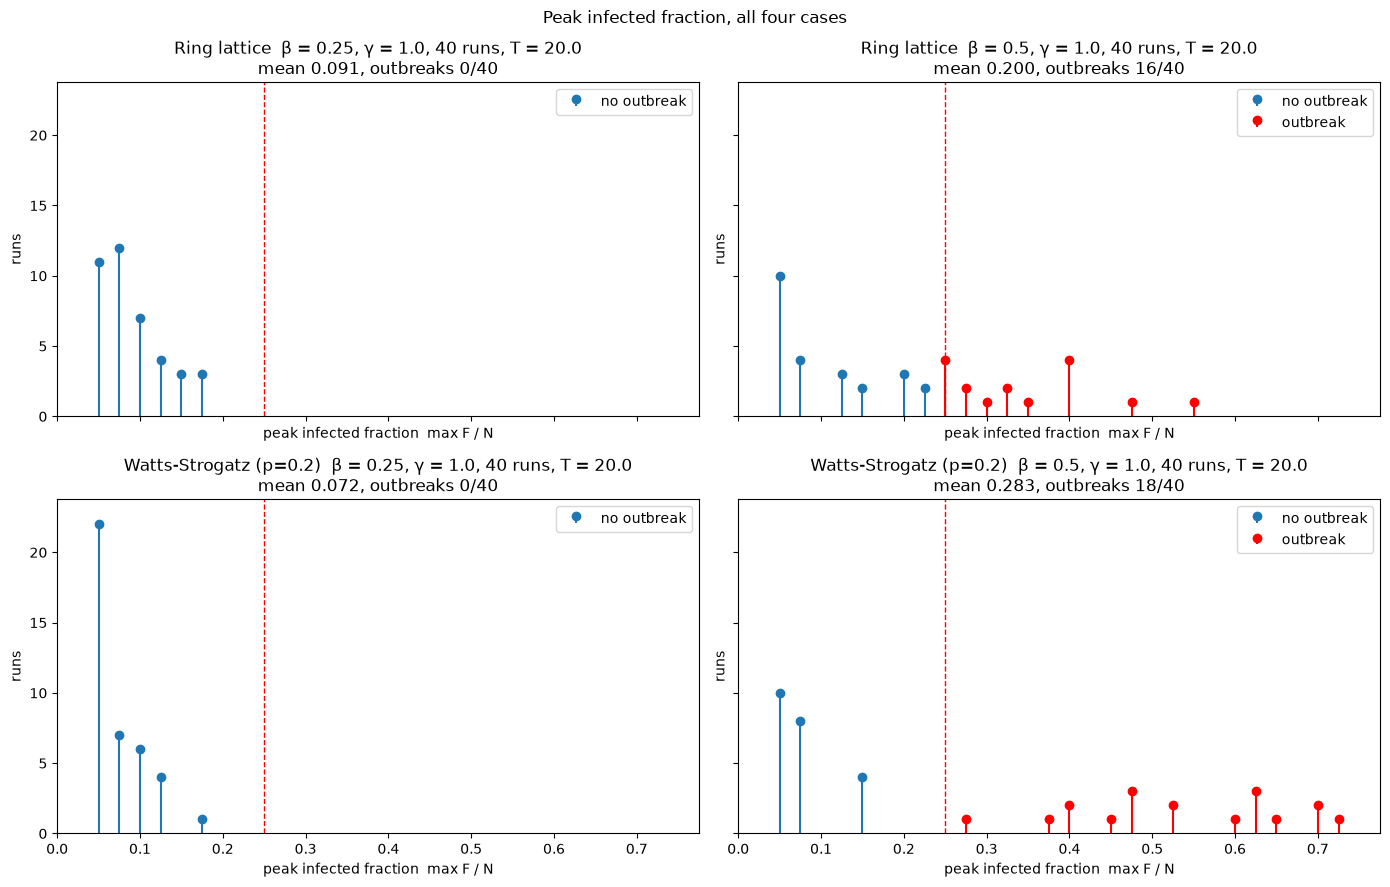

In [675]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, summary in zip(axes.flat, cases):
    plot_peak(ax, summary, title=summary.attrs["title"], lim=lim["peak"])
fig.suptitle("Peak infected fraction, all four cases")
fig.tight_layout()
plt.show()

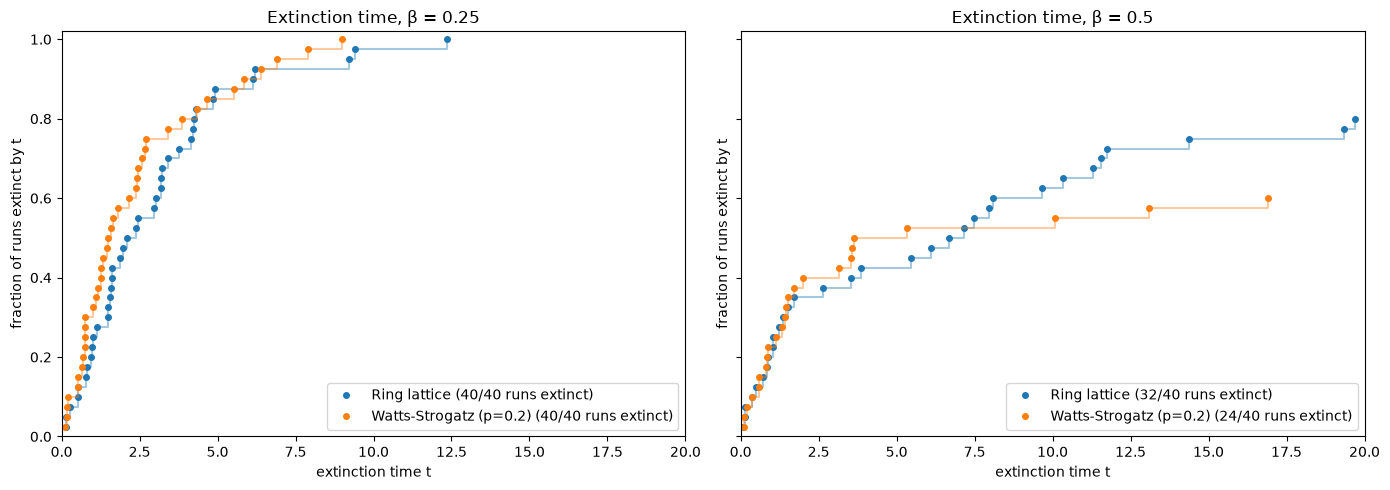

In [676]:
# Extinction time: ring vs Watts–Strogatz overlaid, one panel per β
# (left: case 1 & 3, β = 0.25; right: case 2 & 4, β = 0.5)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (ring, ws) in zip(axes, [(summary_ring_025, summary_watts_strogatz_025),
                                 (summary_ring_05, summary_watts_strogatz_05)]):
    title = f"Extinction time, β = {ring.attrs['beta']}"
    plot_extinction(ax, ring, color="C0", label=ring.attrs["graph_name"], title=title, lim=lim["ext"])
    plot_extinction(ax, ws, color="C1", label=ws.attrs["graph_name"], title=title, lim=lim["ext"])
fig.tight_layout()
plt.show()

#### 5. Comparison and Robustness

Second small-world graph (same $N$, $K$, $p$; different seed), to assess graph-to-graph variability.

G_watts_strogatz properties:
 - Connected: ✔
 - Edges: 80
 - Mean degree: 4.0
 - Clustering coefficient: 0.4
 - deg(0), deg(1): 3, 3
 - L F at start (0, 1 infected), beta = 0.25: -1.00
 - L F at start (0, 1 infected), beta = 0.5: +0.00
G_ws2 (seed 16) properties:
 - Connected: ✔
 - Edges: 80
 - Mean degree: 4.0
 - Clustering coefficient: 0.26
 - deg(0), deg(1): 4, 4
 - L F at start (0, 1 infected), beta = 0.25: -0.50
 - L F at start (0, 1 infected), beta = 0.5: +1.00


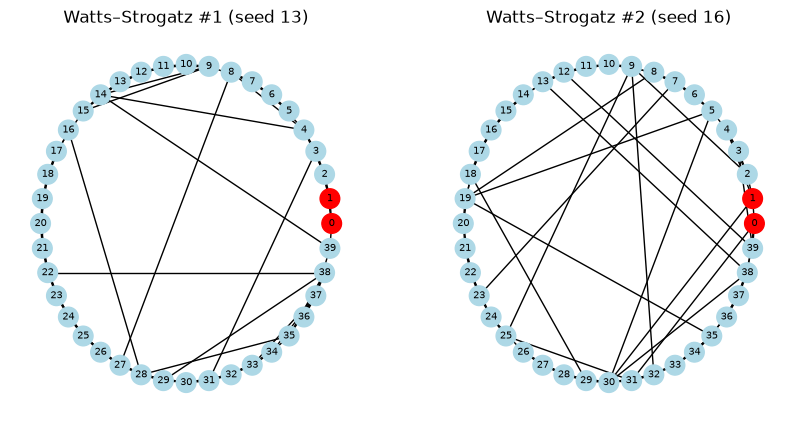

In [677]:
# Second small-world graph: same N, K, p as G_watts_strogatz, different seed.
SEED_WS2 = 16
G_ws2 = nx.watts_strogatz_graph(N, K, P_REWIRE, seed=SEED_WS2)  # rewiring keeps the edge count
assert nx.is_connected(G_ws2), "regenerate with another seed"

for name, G in [("G_watts_strogatz", G_watts_strogatz), (f"G_ws2 (seed {SEED_WS2})", G_ws2)]:
    print(f"{name} properties:")
    print(f" - Connected: {'✔' if nx.is_connected(G) else '✘'}")
    print(f" - Edges: {G.number_of_edges()}")
    print(f" - Mean degree: {2*G.number_of_edges() / G.number_of_nodes()}")
    print(f" - Clustering coefficient: {nx.average_clustering(G):0.2}")
    print(f" - deg(0), deg(1): {G.degree(0)}, {G.degree(1)}")
    for beta in [0.25, 0.5]:
        print(f" - L F at start (0, 1 infected), beta = {beta}: "
              f"{generator_F(G, config(N, [0, 1]), beta, gamma=1.0)['LF']:+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, G, title in zip(axes, [G_watts_strogatz, G_ws2],
                        [f"Watts–Strogatz #1 (seed {SEED_WS})", f"Watts–Strogatz #2 (seed {SEED_WS2})"]):
    # Highlight the initially infected vertices 0 and 1
    colors = ["red" if v in (0, 1) else "lightblue" for v in G.nodes]
    nx.draw(G, pos=nx.circular_layout(G), ax=ax, with_labels=True,
            node_color=colors, node_size=200, font_size=7)
    ax.set_title(title)
plt.show()

Case 5:
- Graph: Watts–Strogatz #2 ($p = 0.2$, new seed)
- Infected vertices: 0 and 1
- $\gamma = 1$, $\beta = 0.25$
- Max time: 20

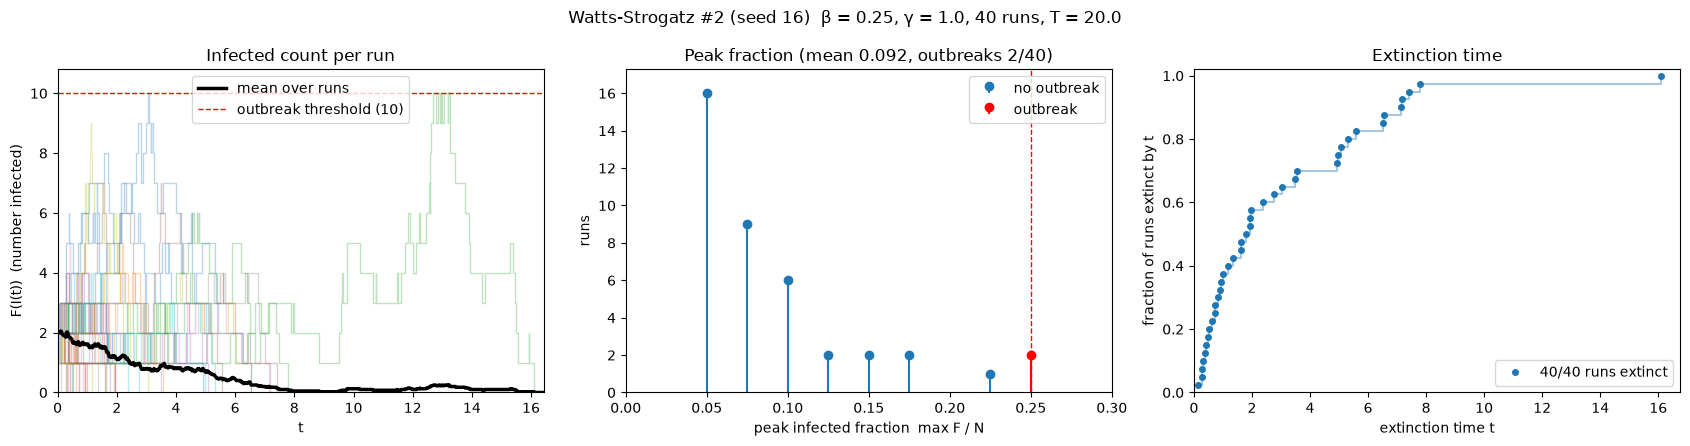

In [678]:
summary_ws2_025 = run_case(G_ws2, 0.25, seed=5500, graph_name=f"Watts-Strogatz #2 (seed {SEED_WS2})")

Case 6:
- Graph: Watts–Strogatz #2 ($p = 0.2$, new seed)
- Infected vertices: 0 and 1
- $\gamma = 1$, $\beta = 0.5$
- Max time: 20

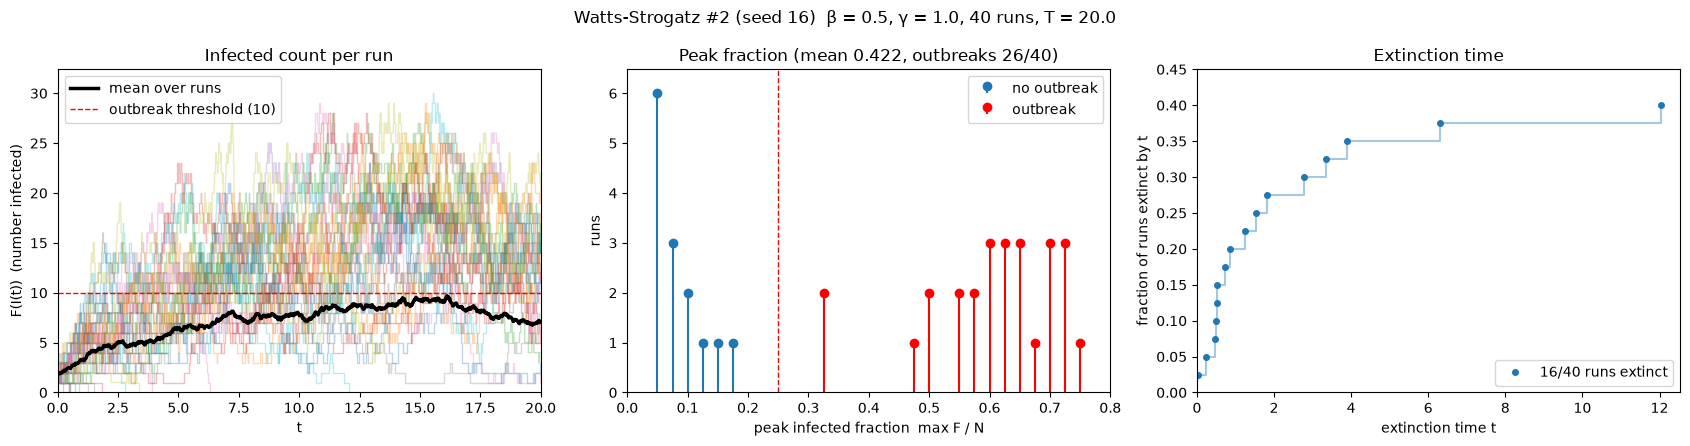

In [679]:
summary_ws2_05 = run_case(G_ws2, 0.5, seed=6600, graph_name=f"Watts-Strogatz #2 (seed {SEED_WS2})")

Comparison across the three graphs

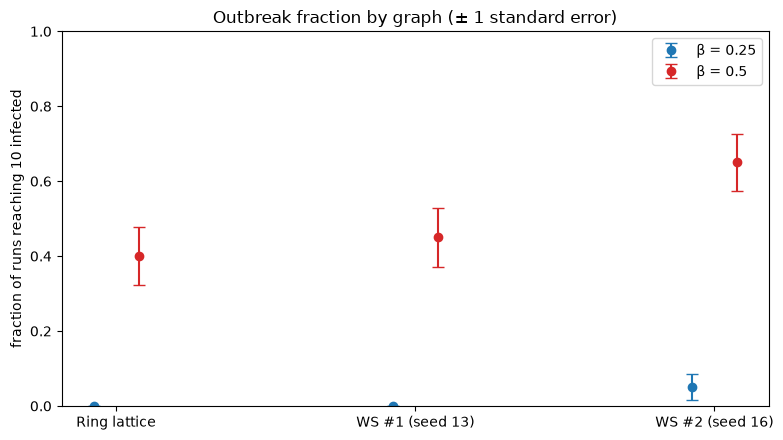

,beta,graph,runs,outbreak fraction,std. error,extinct fraction,mean peak fraction,median extinction time
0,0.25,Ring lattice,40,0.00,0.000,1.0,0.091,2.230
1,0.25,WS #1 (seed 13),40,0.00,0.000,1.0,0.072,1.542
2,0.25,WS #2 (seed 16),40,0.05,0.034,1.0,0.092,1.851
3,0.50,Ring lattice,40,0.40,0.077,0.8,0.200,3.684
4,0.50,WS #1 (seed 13),40,0.45,0.079,0.6,0.283,1.443
5,0.50,WS #2 (seed 16),40,0.65,0.075,0.4,0.422,1.062


In [680]:
# Outbreak fraction (reaching 10 infected by T) per graph and beta, with standard error
# sqrt(p (1 - p) / n_runs) of the estimated fraction.
by_beta = {
    0.25: [summary_ring_025, summary_watts_strogatz_025, summary_ws2_025],
    0.5:  [summary_ring_05, summary_watts_strogatz_05, summary_ws2_05],
}
graph_labels = ["Ring lattice", f"WS #1 (seed {SEED_WS})", f"WS #2 (seed {SEED_WS2})"]

rows = []
for beta, summaries in by_beta.items():
    for label, s in zip(graph_labels, summaries):
        p_hat, n_runs = s["outbreak"].mean(), len(s)
        rows.append({"beta": beta, "graph": label, "runs": n_runs,
                     "outbreak fraction": p_hat,
                     "std. error": np.sqrt(p_hat * (1 - p_hat) / n_runs),
                     "extinct fraction": s["extinct"].mean(),
                     "mean peak fraction": s["peak_fraction"].mean(),
                     "median extinction time": s["extinction_time"].median()})
comparison = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(graph_labels))
for k, (beta, color) in enumerate([(0.25, "C0"), (0.5, "C3")]):
    part = comparison[comparison["beta"] == beta]
    ax.errorbar(x + (k - 0.5) * 0.15, part["outbreak fraction"], yerr=part["std. error"],
                fmt="o", color=color, capsize=4, label=f"β = {beta}")
ax.set_xticks(x, graph_labels)
ax.set_ylim(0, 1)
ax.set_ylabel("fraction of runs reaching 10 infected")
ax.set_title("Outbreak fraction by graph (± 1 standard error)")
ax.legend()
fig.tight_layout()
plt.show()

comparison.round(3)

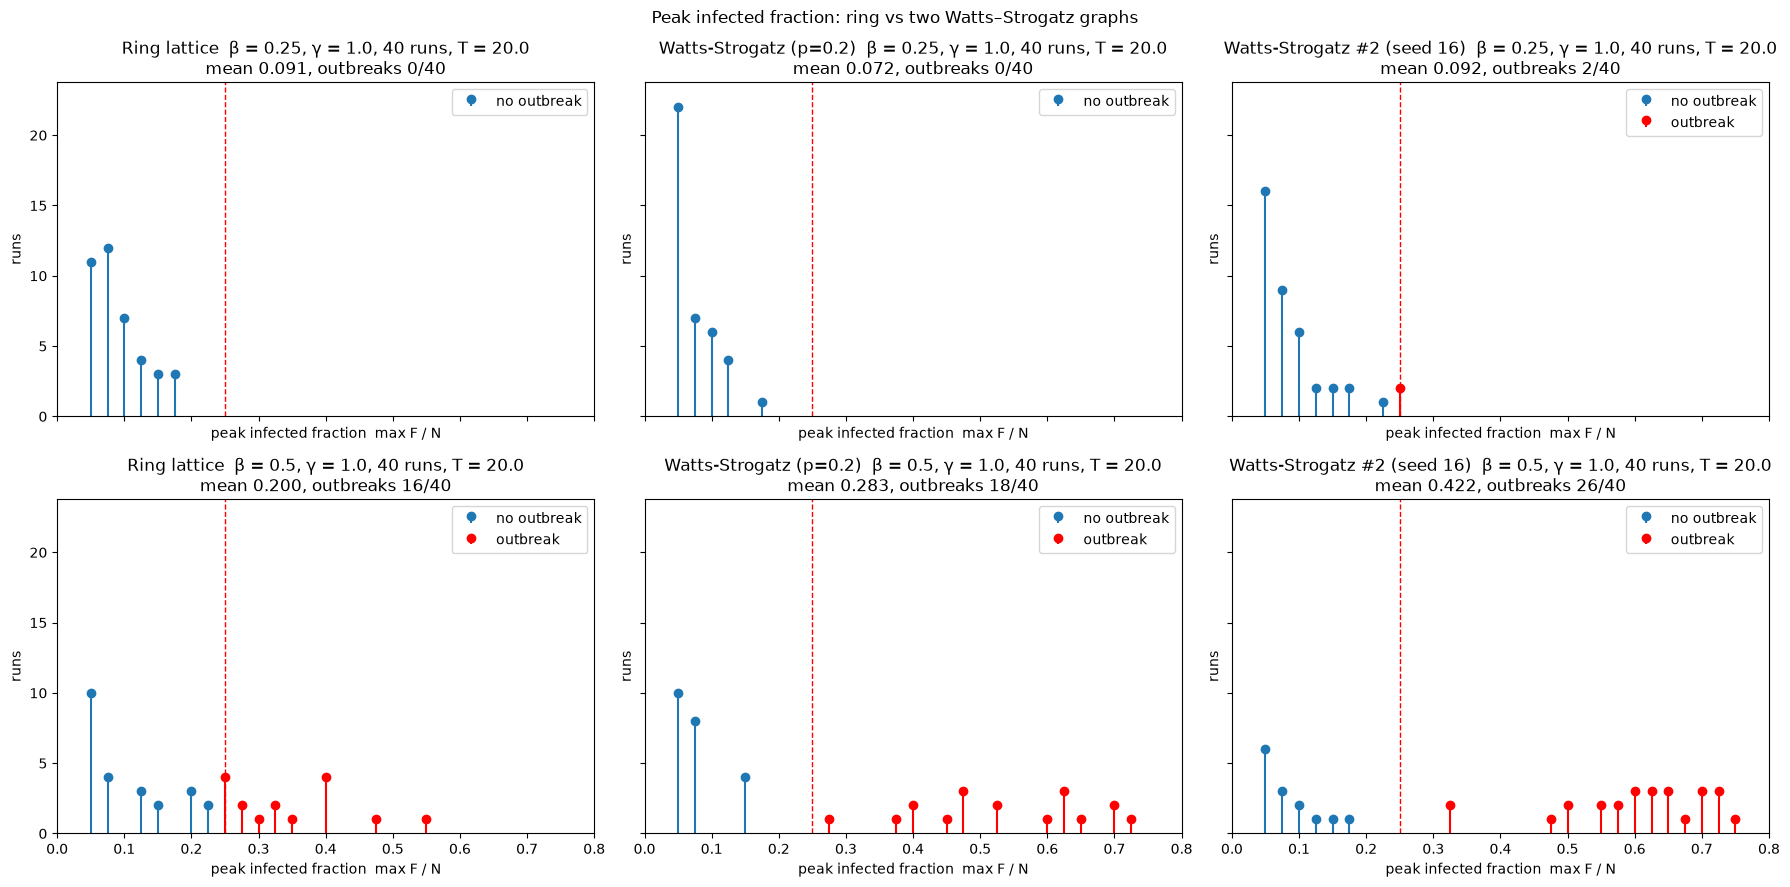

In [681]:
# Peak infected fraction for all three graphs: rows = beta, columns = graph, shared axes
all_cases = by_beta[0.25] + by_beta[0.5]
lim_all = tight_limits(all_cases)

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True, sharey=True)
for row, summaries in zip(axes, by_beta.values()):
    for ax, s in zip(row, summaries):
        plot_peak(ax, s, title=s.attrs["title"], lim=lim_all["peak"])
fig.suptitle("Peak infected fraction: ring vs two Watts–Strogatz graphs")
fig.tight_layout()
plt.show()

Many Watts–Strogatz graphs (same $N$, $K$, $p$, 500 different seeds), to measure graph-to-graph variability beyond a single extra graph.

In [682]:
# Run the same experiment on many Watts–Strogatz graphs (only the rewiring seed changes)
N_GRAPHS = 500
N_RUNS = 40
BETAS = [0.25, 0.5]

sim_seeds = np.random.SeedSequence(7777).generate_state(N_GRAPHS * len(BETAS))
rows = []
graph_seed = 10_000
while len(rows) < N_GRAPHS * len(BETAS):
    G = nx.watts_strogatz_graph(N, K, P_REWIRE, seed=graph_seed)
    graph_seed += 1
    if not nx.is_connected(G):  # regenerate if disconnected
        continue
    for beta in BETAS:
        _, s, _ = run_experiment(G, beta, 1.0, [0, 1], 20.0, N_RUNS, int(sim_seeds[len(rows)]))
        rows.append({"beta": beta, "graph seed": graph_seed - 1,
                     "S-I edges(0,1)": generator_F(G, config(N, [0, 1]), beta, 1.0)["S-I edges"],
                     "clustering": nx.average_clustering(G),
                     "clustering(0,1)": (nx.clustering(G, 0) + nx.clustering(G, 1)) / 2,
                     "outbreak fraction": s["outbreak"].mean()})
many_ws = pd.DataFrame(rows)

# Summary: ring vs the average Watts–Strogatz graph
ring = {0.25: summary_ring_025, 0.5: summary_ring_05}
pd.DataFrame([{
    "beta": beta,
    "ring": ring[beta]["outbreak"].mean(),
    "WS (mean over graphs)": many_ws.loc[many_ws["beta"] == beta, "outbreak fraction"].mean(),
    "% of WS graphs above ring": 100 * (many_ws.loc[many_ws["beta"] == beta, "outbreak fraction"]
                                       > ring[beta]["outbreak"].mean()).mean(),
} for beta in BETAS]).round(2)

,beta,ring,WS (mean over graphs),% of WS graphs above ring
0,0.25,0.0,0.02,58.6
1,0.50,0.4,0.55,90.2


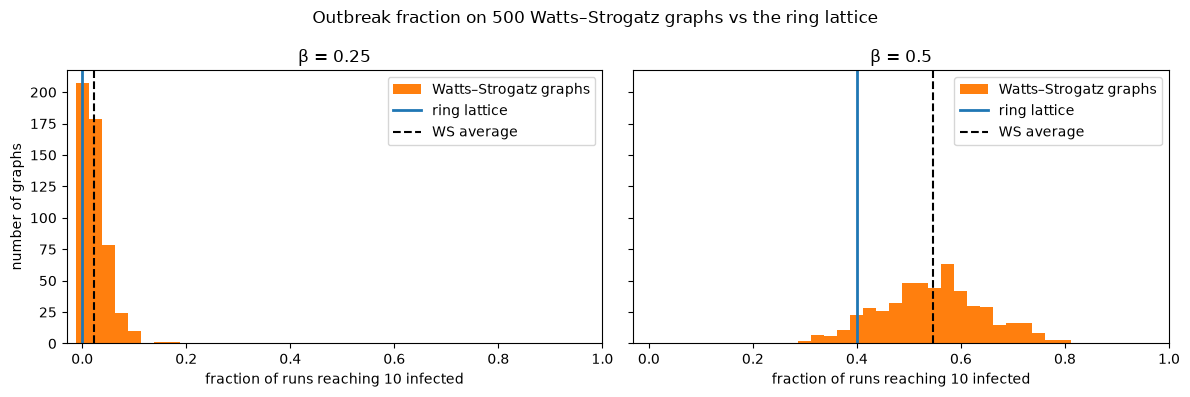

In [683]:
# Outbreak fraction of each Watts–Strogatz graph, compared with the ring lattice
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, beta in zip(axes, BETAS):
    ws = many_ws.loc[many_ws["beta"] == beta, "outbreak fraction"]
    ax.hist(ws, bins=(np.arange(N_RUNS + 2) - 0.5) / N_RUNS, color="C1", label="Watts–Strogatz graphs")
    ax.axvline(ring[beta]["outbreak"].mean(), color="C0", linewidth=2, label="ring lattice")
    ax.axvline(ws.mean(), color="black", linestyle="--", label="WS average")
    ax.set_xlim(-0.03, 1)
    ax.set_xlabel("fraction of runs reaching 10 infected")
    ax.set_title(f"β = {beta}")
    ax.legend()
axes[0].set_ylabel("number of graphs")
fig.suptitle(f"Outbreak fraction on {N_GRAPHS} Watts–Strogatz graphs vs the ring lattice")
fig.tight_layout()
plt.show()

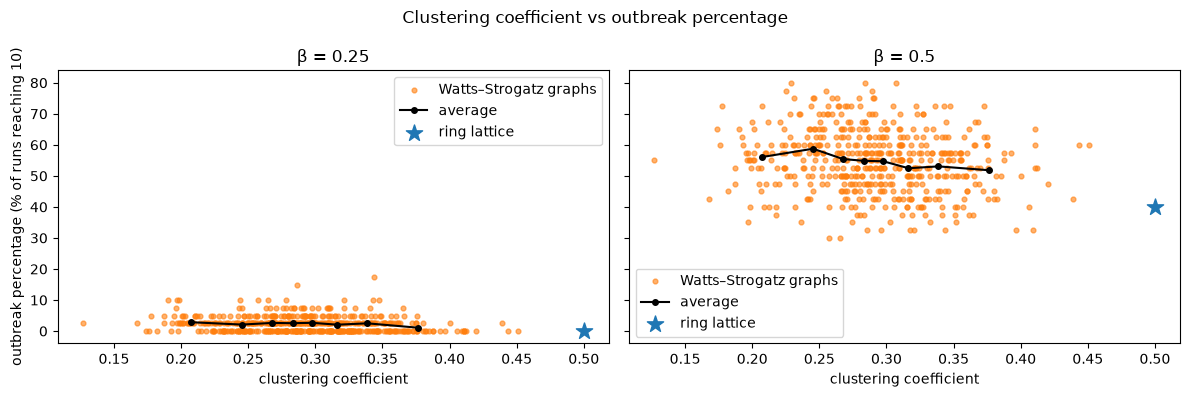

In [687]:
# Clustering coefficient vs outbreak percentage, one point per graph
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, beta in zip(axes, BETAS):
    ws = many_ws[many_ws["beta"] == beta]
    ax.scatter(ws["clustering"], 100 * ws["outbreak fraction"], s=12, alpha=0.6,
               color="C1", label="Watts–Strogatz graphs")
    # Average line: sort graphs into 8 equal-sized groups by clustering, average each group
    groups = pd.qcut(ws["clustering"], q=8, duplicates="drop")
    avg = ws.groupby(groups, observed=True)[["clustering", "outbreak fraction"]].mean()
    ax.plot(avg["clustering"], 100 * avg["outbreak fraction"], "k-o", markersize=4, label="average")
    ax.scatter(nx.average_clustering(G_ring), 100 * ring[beta]["outbreak"].mean(),
               s=150, marker="*", color="C0", zorder=3, label="ring lattice")
    ax.set_xlabel("clustering coefficient")
    ax.set_title(f"β = {beta}")
    ax.legend()
axes[0].set_ylabel("outbreak percentage (% of runs reaching 10)")
fig.suptitle("Clustering coefficient vs outbreak percentage")
fig.tight_layout()
plt.show()

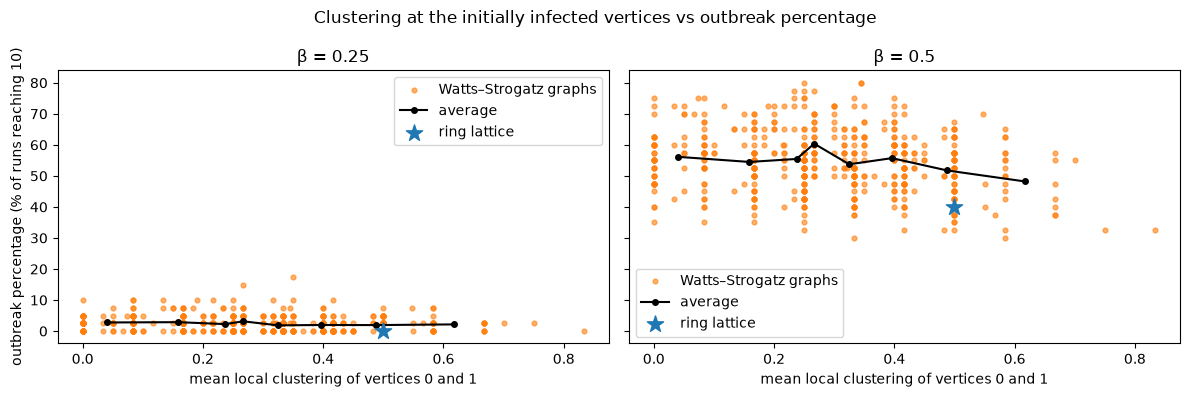

In [686]:
# Local clustering of the initially infected vertices 0 and 1 vs outbreak percentage
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, beta in zip(axes, BETAS):
    ws = many_ws[many_ws["beta"] == beta]
    ax.scatter(ws["clustering(0,1)"], 100 * ws["outbreak fraction"], s=12, alpha=0.6,
               color="C1", label="Watts–Strogatz graphs")
    # Average line: sort graphs into 8 equal-sized groups by clustering, average each group
    groups = pd.qcut(ws["clustering(0,1)"], q=8, duplicates="drop")
    avg = ws.groupby(groups, observed=True)[["clustering(0,1)", "outbreak fraction"]].mean()
    ax.plot(avg["clustering(0,1)"], 100 * avg["outbreak fraction"], "k-o", markersize=4, label="average")
    ring_c01 = (nx.clustering(G_ring, 0) + nx.clustering(G_ring, 1)) / 2
    ax.scatter(ring_c01, 100 * ring[beta]["outbreak"].mean(),
               s=150, marker="*", color="C0", zorder=3, label="ring lattice")
    ax.set_xlabel("mean local clustering of vertices 0 and 1")
    ax.set_title(f"β = {beta}")
    ax.legend()
axes[0].set_ylabel("outbreak percentage (% of runs reaching 10)")
fig.suptitle("Clustering at the initially infected vertices vs outbreak percentage")
fig.tight_layout()
plt.show()

Outbreak percentage against the number of S–I edges in the initial state (vertices 0 and 1 infected). By the generator calculation in section 2, the initial drift is $(\mathcal{L}F)(I(0)) = \beta \cdot \#\{\text{S–I edges}\} - 2\gamma$, so this measures how favourable the neighbourhood of the initially infected vertices is. Each point is one Watts–Strogatz graph (spread horizontally so points do not overlap); the y-axes differ between the two panels.


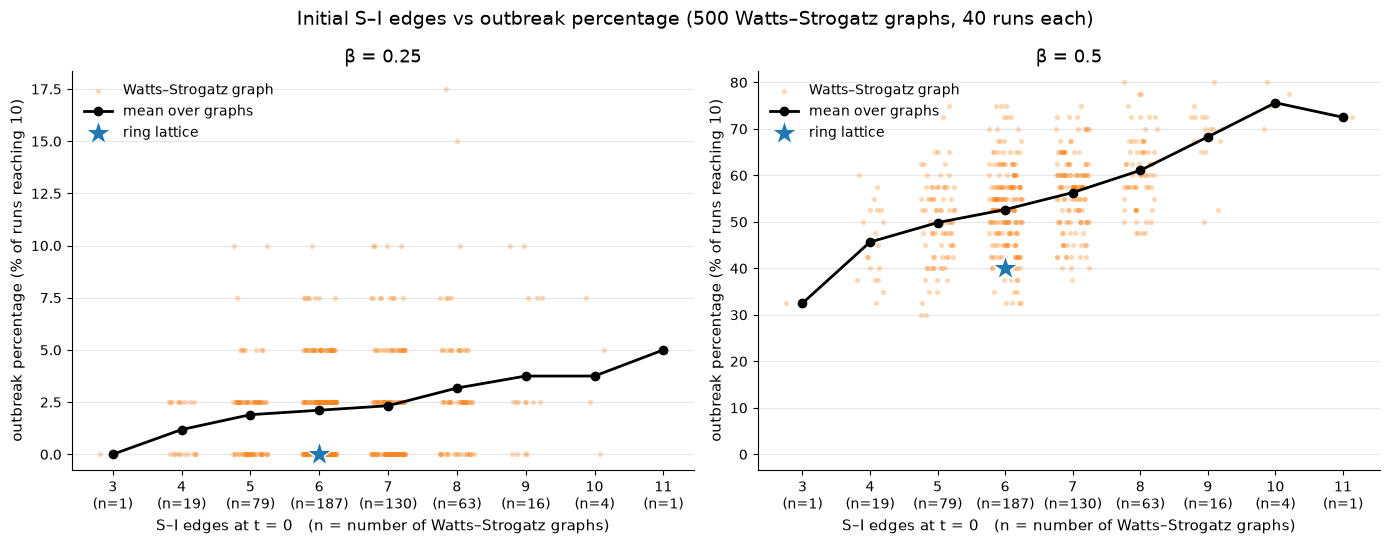

beta,0.25,0.50
"S-I edges(0,1)",,
3,0.0,32.5
4,1.2,45.7
5,1.9,49.8
6,2.1,52.6
7,2.3,56.3
8,3.2,61.1
9,3.8,68.3
10,3.8,75.6
11,5.0,72.5


In [31]:
# Outbreak percentage vs initial S-I edges: one point per Watts–Strogatz graph (jittered
# horizontally), mean over graphs, and the ring lattice for reference.
jitter = np.random.default_rng(0)  # only for plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, beta in zip(axes, BETAS):
    ws = many_ws[many_ws["beta"] == beta]
    stats = ws.groupby("S-I edges(0,1)")["outbreak fraction"].agg(["mean", "size"])
    edges = stats.index.to_numpy()

    ax.scatter(ws["S-I edges(0,1)"] + jitter.uniform(-0.25, 0.25, len(ws)),
               100 * ws["outbreak fraction"], s=14, alpha=0.3, color="C1", linewidth=0,
               label="Watts–Strogatz graph")
    ax.plot(edges, 100 * stats["mean"], "-o", color="black", linewidth=2, markersize=6,
            label="mean over graphs")
    ring_si = generator_F(G_ring, config(N, [0, 1]), beta, 1.0)["S-I edges"]
    ax.scatter(ring_si, 100 * ring[beta]["outbreak"].mean(), s=380, marker="*", color="C0",
               edgecolor="white", linewidth=1, zorder=4, label="ring lattice")

    ax.set_xticks(edges, [f"{k}\n(n={n})" for k, n in stats["size"].items()], fontsize=10)
    ax.set_xlabel("S–I edges at t = 0   (n = number of Watts–Strogatz graphs)", fontsize=11)
    ax.set_ylabel("outbreak percentage (% of runs reaching 10)", fontsize=11)
    ax.set_title(f"β = {beta}", fontsize=13)
    ax.set_ylim(bottom=-0.04 * ax.get_ylim()[1])  # keep points at 0% fully visible
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", fontsize=10, frameon=False)
fig.suptitle(f"Initial S–I edges vs outbreak percentage ({N_GRAPHS} Watts–Strogatz graphs, {N_RUNS} runs each)",
             fontsize=14)
fig.tight_layout()
plt.show()

# Mean outbreak percentage per S-I edge count (rows) and beta (columns)
(100 * many_ws.pivot_table(index="S-I edges(0,1)", columns="beta",
                           values="outbreak fraction", aggfunc="mean")).round(1)
